### scikit-learn 3: Regression - Übungen

Bei der **Regression** sagt ein Modell keine Klasse, sondern eine **Zahl** voraus: die Miete einer Wohnung, die Anzahl ausgeliehener Fahrräder an einem Tag.
Du lernst die lineare Regression mit einem und mit mehreren Merkmalen kennen, Fehlermaße für Zahlen, gekrümmte Zusammenhänge mit Polynomen
und wie Bäume und k-nächste Nachbarn Zahlen vorhersagen. Wie bei der Klassifikation geht es dabei immer auch um Überanpassung.

Die Reihe hat vier Notebooks:

1. Grundlagen: Merkmale und Zielwerte, das erste Modell, Trainings- und Testdaten, Skalieren
2. Klassifikation: k-nächste Nachbarn, Entscheidungsbäume, logistische Regression, neuronale Netze, Kreuzvalidierung
3. **Regression**: Zahlen vorhersagen, Überanpassung (dieses Notebook)
4. Unüberwachtes Lernen: Clustering, Dimensionen reduzieren, Ziffernerkennung

Vorausgesetzt werden *scikit-learn: Grundlagen* und *scikit-learn: Klassifikation* (Kreuzvalidierung). Die Regressionsgerade aus *numpy: Mathematik* ist hilfreich.

**Tabellen anzeigen:** Steht eine Tabelle (ein DataFrame) in der **letzten Zeile** einer Zelle, zeigt JupyterLab sie als Tabelle an. Mehrere Tabellen
in einer Zelle zeigt man mit `display(df)` an. Einzelne Werte gibt man wie gewohnt mit `print()` aus. Die erwarteten Ausgaben in den Aufgaben sehen genauso aus.

Jeder Abschnitt beginnt mit kurzen Erklärungen und Beispielen. Führe die Beispiele aus und probiere sie ruhig ein wenig aus.
Danach folgen viele kleine Übungen. Wenn etwas vorgegeben ist, steht es schon in der Codezelle.

Beim ersten `import sklearn` lädt der Browser die Pakete nach. Das dauert einige Sekunden.

Unter den Aufgaben kannst du jeweils die Lösung aufklappen. Versuche es aber immer zuerst selbst!
Bei den Aufgaben „Was wird ausgegeben?“ überlegst du zuerst, führst dann die Zelle aus und vergleichst.
Die aufklappbare Lösung erklärt dort, wie die Ausgabe zustande kommt.

#### Beispieldaten anlegen

**Führe diese Zelle zuerst aus.** Sie erzeugt mit Zufallszahlen (festem Seed) zwei ausgedachte Tabellen:

- `wohnungen.csv`: 120 Mietwohnungen mit Wohnfläche in m², Anzahl der Zimmer, Baujahr, Entfernung zur Innenstadt in km und Kaltmiete in €.
- `fahrrad.csv`: 150 Tage eines Fahrradverleihs mit der Tagestemperatur in °C und der Anzahl der ausgeliehenen Räder.

Wie die Zahlen entstehen, musst du nicht verstehen; die Modelle sollen die Zusammenhänge ja selbst finden. Die erste Zeile blendet eine harmlose Meldung aus, die das Python im Browser sonst beim ersten Training anzeigt.

In [ ]:
import warnings
warnings.filterwarnings('ignore', message='JsProxy')   # harmlose Meldung des Browser-Pythons ausblenden

import numpy as np
import pandas as pd

rng = np.random.default_rng(2024)
n = 120
flaeche = rng.uniform(25, 140, n).round()
zimmer = np.clip((flaeche / 30).round() + rng.integers(0, 2, n), 1, 5)
baujahr = rng.integers(1950, 2024, n)
entfernung = rng.uniform(0.5, 15, n).round(1)
miete = (150 + 9.5 * flaeche + 40 * zimmer + 2 * (baujahr - 1950) - 18 * entfernung + rng.normal(0, 60, n)).round()
pd.DataFrame({'flaeche': flaeche.astype(int), 'zimmer': zimmer.astype(int), 'baujahr': baujahr,
              'entfernung': entfernung, 'miete': miete.astype(int)}).to_csv('wohnungen.csv', index=False)

temperatur = rng.uniform(-5, 35, 150).round(2)
ausleihen = np.clip(900 - 1.6 * (temperatur - 24) ** 2 + rng.normal(0, 60, 150), 0, None).round()
pd.DataFrame({'temperatur': temperatur, 'ausleihen': ausleihen.astype(int)}).to_csv('fahrrad.csv', index=False)
print('Angelegt: wohnungen.csv, fahrrad.csv')

## 1. Eine Gerade durch die Punkte

#### `LinearRegression`

Die **lineare Regression** legt eine Gerade `y = m·x + b` so durch die Punkte, dass die Summe der quadrierten Abweichungen am kleinsten ist
(wie `np.polyfit(x, y, 1)` in *numpy: Mathematik*). In scikit-learn wird sie wie jedes Modell benutzt:

- `modell = LinearRegression()`, `modell.fit(X, y)`: `X` ist eine Tabelle (auch bei nur einem Merkmal: doppelte Klammern), `y` eine Spalte mit Zahlen.
- `modell.coef_` enthält die Steigung `m` (ein Array, ein Wert pro Merkmal), `modell.intercept_` den Achsenabschnitt `b`.
- `modell.predict(X_neu)` berechnet die Werte auf der Geraden.

In [ ]:
import pandas as pd

wohnungen = pd.read_csv('wohnungen.csv')
from sklearn.linear_model import LinearRegression

X = wohnungen[['flaeche']]
y = wohnungen['miete']
modell = LinearRegression()
modell.fit(X, y)
print(modell.coef_.round(2), round(modell.intercept_, 2))
neu = pd.DataFrame({'flaeche': [40, 80, 120]})
print(modell.predict(neu).round())

#### Zeichnen

Die Gerade zeichnet man, indem man `predict()` für zwei (oder viele) Werte aufruft und die Ergebnisse mit `plt.plot()` verbindet.

In [ ]:
import pandas as pd

wohnungen = pd.read_csv('wohnungen.csv')
from sklearn.linear_model import LinearRegression
import matplotlib.pyplot as plt

X = wohnungen[['flaeche']]
y = wohnungen['miete']
modell = LinearRegression()
modell.fit(X, y)
x = pd.DataFrame({'flaeche': [20, 150]})
plt.scatter(X['flaeche'], y, s=10)
plt.plot(x['flaeche'], modell.predict(x), color='red')
plt.xlabel('Fläche in m²')
plt.ylabel('Miete in €')
plt.show()

#### Aufgabe 1.1

Zeige die ersten 5 Wohnungen und die Kennzahlen (`describe()`, auf eine Nachkommastelle gerundet) der Tabelle an.

**Erwartete Ausgabe:**

<table style="margin-left: 0">
  <thead>
    <tr>
      <th style="text-align: right"></th>
      <th style="text-align: right">flaeche</th>
      <th style="text-align: right">zimmer</th>
      <th style="text-align: right">baujahr</th>
      <th style="text-align: right">entfernung</th>
      <th style="text-align: right">miete</th>
    </tr>
  </thead>
  <tbody>
    <tr>
      <th style="text-align: right">0</th>
      <td style="text-align: right">103</td>
      <td style="text-align: right">3</td>
      <td style="text-align: right">2018</td>
      <td style="text-align: right">14.1</td>
      <td style="text-align: right">1158</td>
    </tr>
    <tr>
      <th style="text-align: right">1</th>
      <td style="text-align: right">50</td>
      <td style="text-align: right">3</td>
      <td style="text-align: right">2004</td>
      <td style="text-align: right">14.0</td>
      <td style="text-align: right">564</td>
    </tr>
    <tr>
      <th style="text-align: right">2</th>
      <td style="text-align: right">61</td>
      <td style="text-align: right">2</td>
      <td style="text-align: right">1973</td>
      <td style="text-align: right">7.6</td>
      <td style="text-align: right">624</td>
    </tr>
    <tr>
      <th style="text-align: right">3</th>
      <td style="text-align: right">117</td>
      <td style="text-align: right">5</td>
      <td style="text-align: right">1958</td>
      <td style="text-align: right">5.5</td>
      <td style="text-align: right">1414</td>
    </tr>
    <tr>
      <th style="text-align: right">4</th>
      <td style="text-align: right">140</td>
      <td style="text-align: right">5</td>
      <td style="text-align: right">1985</td>
      <td style="text-align: right">3.1</td>
      <td style="text-align: right">1747</td>
    </tr>
  </tbody>
</table>

<table style="margin-left: 0">
  <thead>
    <tr>
      <th style="text-align: right"></th>
      <th style="text-align: right">flaeche</th>
      <th style="text-align: right">zimmer</th>
      <th style="text-align: right">baujahr</th>
      <th style="text-align: right">entfernung</th>
      <th style="text-align: right">miete</th>
    </tr>
  </thead>
  <tbody>
    <tr>
      <th style="text-align: right">count</th>
      <td style="text-align: right">120.0</td>
      <td style="text-align: right">120.0</td>
      <td style="text-align: right">120.0</td>
      <td style="text-align: right">120.0</td>
      <td style="text-align: right">120.0</td>
    </tr>
    <tr>
      <th style="text-align: right">mean</th>
      <td style="text-align: right">74.6</td>
      <td style="text-align: right">3.0</td>
      <td style="text-align: right">1988.8</td>
      <td style="text-align: right">7.5</td>
      <td style="text-align: right">925.5</td>
    </tr>
    <tr>
      <th style="text-align: right">std</th>
      <td style="text-align: right">31.0</td>
      <td style="text-align: right">1.1</td>
      <td style="text-align: right">21.1</td>
      <td style="text-align: right">4.2</td>
      <td style="text-align: right">352.9</td>
    </tr>
    <tr>
      <th style="text-align: right">min</th>
      <td style="text-align: right">26.0</td>
      <td style="text-align: right">1.0</td>
      <td style="text-align: right">1951.0</td>
      <td style="text-align: right">0.6</td>
      <td style="text-align: right">280.0</td>
    </tr>
    <tr>
      <th style="text-align: right">25%</th>
      <td style="text-align: right">50.0</td>
      <td style="text-align: right">2.0</td>
      <td style="text-align: right">1970.8</td>
      <td style="text-align: right">4.0</td>
      <td style="text-align: right">648.0</td>
    </tr>
    <tr>
      <th style="text-align: right">50%</th>
      <td style="text-align: right">69.0</td>
      <td style="text-align: right">3.0</td>
      <td style="text-align: right">1991.5</td>
      <td style="text-align: right">7.2</td>
      <td style="text-align: right">883.0</td>
    </tr>
    <tr>
      <th style="text-align: right">75%</th>
      <td style="text-align: right">96.0</td>
      <td style="text-align: right">4.0</td>
      <td style="text-align: right">2007.0</td>
      <td style="text-align: right">11.0</td>
      <td style="text-align: right">1185.5</td>
    </tr>
    <tr>
      <th style="text-align: right">max</th>
      <td style="text-align: right">140.0</td>
      <td style="text-align: right">5.0</td>
      <td style="text-align: right">2023.0</td>
      <td style="text-align: right">14.9</td>
      <td style="text-align: right">1747.0</td>
    </tr>
  </tbody>
</table>

In [ ]:
import pandas as pd

wohnungen = pd.read_csv('wohnungen.csv')
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import pandas as pd

wohnungen = pd.read_csv('wohnungen.csv')
display(wohnungen.head())
wohnungen.describe().round(1)
```

</details>

#### Aufgabe 1.2

Lege eine Gerade durch die Punkte (Entfernung, Miete). Gib Steigung und Achsenabschnitt aus (2 Nachkommastellen). Wie viel billiger ist eine Wohnung
nach dieser Geraden pro km Entfernung?

**Erwartete Ausgabe:**

```
-19.76 1073.61
```

In [ ]:
import pandas as pd

wohnungen = pd.read_csv('wohnungen.csv')
from sklearn.linear_model import LinearRegression
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import pandas as pd

wohnungen = pd.read_csv('wohnungen.csv')
from sklearn.linear_model import LinearRegression
X = wohnungen[['entfernung']]
y = wohnungen['miete']
modell = LinearRegression()
modell.fit(X, y)
print(f'{modell.coef_[0]:.2f} {modell.intercept_:.2f}')
```

</details>

#### Aufgabe 1.3

Vergleiche für (Fläche, Miete) die Gerade von `LinearRegression` mit `np.polyfit(..., 1)` (Steigung und Achsenabschnitt, 2 Nachkommastellen).

**Erwartete Ausgabe:**

```
10.83 117.30
10.83 117.30
```

In [ ]:
import pandas as pd

wohnungen = pd.read_csv('wohnungen.csv')
import numpy as np
from sklearn.linear_model import LinearRegression
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import pandas as pd

wohnungen = pd.read_csv('wohnungen.csv')
import numpy as np
from sklearn.linear_model import LinearRegression
modell = LinearRegression()
modell.fit(wohnungen[['flaeche']], wohnungen['miete'])
print(f'{modell.coef_[0]:.2f} {modell.intercept_:.2f}')
m, b = np.polyfit(wohnungen['flaeche'], wohnungen['miete'], 1)
print(f'{m:.2f} {b:.2f}')
```

</details>

#### Aufgabe 1.4

Sage mit der Geraden für (Fläche, Miete) die Miete von Wohnungen mit 30, 60, 90 und 150 m² voraus (ganze Euro). 150 m² liegt außerhalb der Daten
(**Extrapolation**): Dort ist die Vorhersage unsicher.

**Erwartete Ausgabe:**

```
[ 442.  767. 1092. 1742.]
```

In [ ]:
import pandas as pd

wohnungen = pd.read_csv('wohnungen.csv')
from sklearn.linear_model import LinearRegression
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import pandas as pd

wohnungen = pd.read_csv('wohnungen.csv')
from sklearn.linear_model import LinearRegression
modell = LinearRegression()
modell.fit(wohnungen[['flaeche']], wohnungen['miete'])
neu = pd.DataFrame({'flaeche': [30, 60, 90, 150]})
print(modell.predict(neu).round())
```

</details>

#### Aufgabe 1.5

Ab welcher Fläche sagt die Gerade mindestens 1000 € Miete voraus? Löse `m·x + b = 1000` nach `x` auf (eine Nachkommastelle).

**Erwartete Ausgabe:**

```
81.5
```

In [ ]:
import pandas as pd

wohnungen = pd.read_csv('wohnungen.csv')
from sklearn.linear_model import LinearRegression
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import pandas as pd

wohnungen = pd.read_csv('wohnungen.csv')
from sklearn.linear_model import LinearRegression
modell = LinearRegression()
modell.fit(wohnungen[['flaeche']], wohnungen['miete'])
print(f'{(1000 - modell.intercept_) / modell.coef_[0]:.1f}')
```

</details>

#### Aufgabe 1.6

Zeichne die Fahrrad-Daten (Temperatur, Ausleihen) als Punkte und die Regressionsgerade als rote Linie (von -5 bis 35 °C). Eine Gerade passt hier schlecht:
Bei großer Hitze werden wieder weniger Räder ausgeliehen.

**Erwartete Ausgabe:**



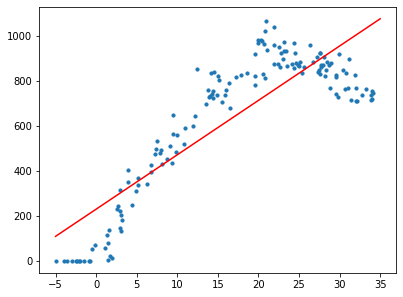

In [ ]:
import pandas as pd

fahrrad = pd.read_csv('fahrrad.csv')
from sklearn.linear_model import LinearRegression
import matplotlib.pyplot as plt
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import pandas as pd

fahrrad = pd.read_csv('fahrrad.csv')
from sklearn.linear_model import LinearRegression
import matplotlib.pyplot as plt
modell = LinearRegression()
modell.fit(fahrrad[['temperatur']], fahrrad['ausleihen'])
x = pd.DataFrame({'temperatur': [-5, 35]})
plt.scatter(fahrrad['temperatur'], fahrrad['ausleihen'], s=10)
plt.plot(x['temperatur'], modell.predict(x), color='red')
plt.show()
```

</details>

#### Aufgabe 1.7

Was wird ausgegeben? Überlege zuerst, was ausgegeben wird. Führe dann die Zelle aus und vergleiche.

In [ ]:
import pandas as pd
from sklearn.linear_model import LinearRegression

X = pd.DataFrame({'x': [0, 1, 2, 3]})
y = [1, 3, 5, 7]
modell = LinearRegression()
modell.fit(X, y)
print(round(modell.coef_[0], 4), round(modell.intercept_, 4))
print(modell.predict(pd.DataFrame({'x': [10]})).round(4))

<details>
<summary>Lösung anzeigen (erst selbst überlegen!)</summary>

**Ausgabe:**

```
2.0 1.0
[21.]
```

Die Punkte liegen genau auf der Geraden `y = 2x + 1`: Steigung `2.0`, Achsenabschnitt `1.0`.
Für `x = 10` ergibt sich `2 · 10 + 1 = 21`, als Array `[21.]`.

</details>

## 2. Mehrere Merkmale

#### Eine Ebene statt einer Geraden

Mit mehreren Merkmalen berechnet die lineare Regression `y = m₁·x₁ + m₂·x₂ + ... + b`. Jeder Koeffizient `mᵢ` gibt an, um wie viel sich `y` ändert,
wenn `xᵢ` um 1 steigt **und alle anderen Merkmale gleich bleiben**. Mit `pd.Series(modell.coef_, index=X.columns)` sieht man, welcher Koeffizient zu
welchem Merkmal gehört.

In [ ]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression

wohnungen = pd.read_csv('wohnungen.csv')
X = wohnungen[['flaeche', 'zimmer', 'baujahr', 'entfernung']]
y = wohnungen['miete']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=0)

modell = LinearRegression()
modell.fit(X_train, y_train)
print(pd.Series(modell.coef_, index=X.columns).round(2))
print(f'{modell.intercept_:.2f}')

#### Aufgabe 2.1

Trainiere die lineare Regression mit allen vier Merkmalen auf den Trainingsdaten und sage die Miete einer Wohnung mit 75 m², 3 Zimmern, Baujahr 1995
und 4.5 km Entfernung voraus (ganze Euro).

**Erwartete Ausgabe:**

```
[999.]
```

In [ ]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression

wohnungen = pd.read_csv('wohnungen.csv')
X = wohnungen[['flaeche', 'zimmer', 'baujahr', 'entfernung']]
y = wohnungen['miete']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=0)
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression

wohnungen = pd.read_csv('wohnungen.csv')
X = wohnungen[['flaeche', 'zimmer', 'baujahr', 'entfernung']]
y = wohnungen['miete']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=0)
modell = LinearRegression()
modell.fit(X_train, y_train)
neu = pd.DataFrame({'flaeche': [75], 'zimmer': [3], 'baujahr': [1995], 'entfernung': [4.5]})
print(modell.predict(neu).round())
```

</details>

#### Aufgabe 2.2

Wie viel teurer ist nach dem Modell eine sonst gleiche Wohnung, die 10 m² größer ist? Und eine, die 20 Jahre neuer ist? (Koeffizienten mal 10 bzw. mal 20,
2 Nachkommastellen)

**Erwartete Ausgabe:**

```
97.06
36.60
```

In [ ]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression

wohnungen = pd.read_csv('wohnungen.csv')
X = wohnungen[['flaeche', 'zimmer', 'baujahr', 'entfernung']]
y = wohnungen['miete']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=0)
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression

wohnungen = pd.read_csv('wohnungen.csv')
X = wohnungen[['flaeche', 'zimmer', 'baujahr', 'entfernung']]
y = wohnungen['miete']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=0)
modell = LinearRegression()
modell.fit(X_train, y_train)
koeffizienten = pd.Series(modell.coef_, index=X.columns)
print(f"{koeffizienten['flaeche'] * 10:.2f}")
print(f"{koeffizienten['baujahr'] * 20:.2f}")
```

</details>

#### Aufgabe 2.3

Zeige für die ersten 5 Testwohnungen eine Tabelle mit der echten Miete (`miete`), der Vorhersage (`vorhersage`, ganze Euro) und der Abweichung
(`abweichung` = Vorhersage − echte Miete) an.

**Erwartete Ausgabe:**

<table style="margin-left: 0">
  <thead>
    <tr>
      <th style="text-align: right"></th>
      <th style="text-align: right">miete</th>
      <th style="text-align: right">vorhersage</th>
      <th style="text-align: right">abweichung</th>
    </tr>
  </thead>
  <tbody>
    <tr>
      <th style="text-align: right">48</th>
      <td style="text-align: right">795</td>
      <td style="text-align: right">731.0</td>
      <td style="text-align: right">-64.0</td>
    </tr>
    <tr>
      <th style="text-align: right">94</th>
      <td style="text-align: right">1272</td>
      <td style="text-align: right">1290.0</td>
      <td style="text-align: right">18.0</td>
    </tr>
    <tr>
      <th style="text-align: right">95</th>
      <td style="text-align: right">608</td>
      <td style="text-align: right">611.0</td>
      <td style="text-align: right">3.0</td>
    </tr>
    <tr>
      <th style="text-align: right">8</th>
      <td style="text-align: right">889</td>
      <td style="text-align: right">903.0</td>
      <td style="text-align: right">14.0</td>
    </tr>
    <tr>
      <th style="text-align: right">97</th>
      <td style="text-align: right">1190</td>
      <td style="text-align: right">1209.0</td>
      <td style="text-align: right">19.0</td>
    </tr>
  </tbody>
</table>

In [ ]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression

wohnungen = pd.read_csv('wohnungen.csv')
X = wohnungen[['flaeche', 'zimmer', 'baujahr', 'entfernung']]
y = wohnungen['miete']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=0)
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression

wohnungen = pd.read_csv('wohnungen.csv')
X = wohnungen[['flaeche', 'zimmer', 'baujahr', 'entfernung']]
y = wohnungen['miete']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=0)
modell = LinearRegression()
modell.fit(X_train, y_train)
ergebnis = pd.DataFrame({'miete': y_test, 'vorhersage': modell.predict(X_test).round()})
ergebnis['abweichung'] = ergebnis['vorhersage'] - ergebnis['miete']
ergebnis.head()
```

</details>

#### Aufgabe 2.4

Welches einzelne Merkmal erklärt die Miete am besten? Trainiere für jedes der vier Merkmale eine Regression nur mit diesem Merkmal und gib das Merkmal und
`score()` auf den Testdaten aus (3 Nachkommastellen). `score()` ist bei der Regression das Bestimmtheitsmaß R² (Abschnitt 3).

**Erwartete Ausgabe:**

```
flaeche 0.913
zimmer 0.726
baujahr -0.032
entfernung -0.067
```

In [ ]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression

wohnungen = pd.read_csv('wohnungen.csv')
X = wohnungen[['flaeche', 'zimmer', 'baujahr', 'entfernung']]
y = wohnungen['miete']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=0)
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression

wohnungen = pd.read_csv('wohnungen.csv')
X = wohnungen[['flaeche', 'zimmer', 'baujahr', 'entfernung']]
y = wohnungen['miete']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=0)
for merkmal in ['flaeche', 'zimmer', 'baujahr', 'entfernung']:
    modell = LinearRegression()
    modell.fit(X_train[[merkmal]], y_train)
    print(merkmal, f'{modell.score(X_test[[merkmal]], y_test):.3f}')
```

</details>

#### Aufgabe 2.5

Zeichne ein Streudiagramm der echten Mieten der Testwohnungen (x-Achse) gegen die Vorhersagen (y-Achse) und eine gestrichelte Linie von (400 | 400)
bis (1800 | 1800). Bei perfekten Vorhersagen lägen alle Punkte auf dieser Linie.

**Erwartete Ausgabe:**



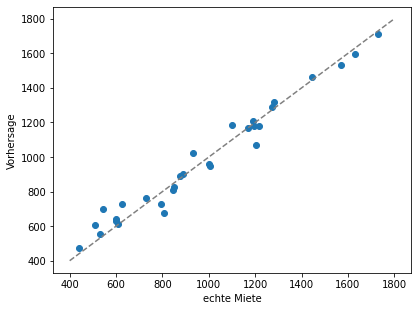

In [ ]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression

wohnungen = pd.read_csv('wohnungen.csv')
X = wohnungen[['flaeche', 'zimmer', 'baujahr', 'entfernung']]
y = wohnungen['miete']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=0)
import matplotlib.pyplot as plt
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression

wohnungen = pd.read_csv('wohnungen.csv')
X = wohnungen[['flaeche', 'zimmer', 'baujahr', 'entfernung']]
y = wohnungen['miete']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=0)
import matplotlib.pyplot as plt
modell = LinearRegression()
modell.fit(X_train, y_train)
plt.scatter(y_test, modell.predict(X_test))
plt.plot([400, 1800], [400, 1800], linestyle='--', color='gray')
plt.xlabel('echte Miete')
plt.ylabel('Vorhersage')
plt.show()
```

</details>

#### Aufgabe 2.6

Was wird ausgegeben? Überlege zuerst, was ausgegeben wird. Führe dann die Zelle aus und vergleiche.

In [ ]:
import pandas as pd
from sklearn.linear_model import LinearRegression

X = pd.DataFrame({'a': [0, 1, 0, 1], 'b': [0, 0, 1, 1]})
y = [5, 7, 8, 10]
modell = LinearRegression()
modell.fit(X, y)
print(modell.coef_.round(4), round(modell.intercept_, 4))

<details>
<summary>Lösung anzeigen (erst selbst überlegen!)</summary>

**Ausgabe:**

```
[2. 3.] 5.0
```

Die Werte passen genau zu `y = 2a + 3b + 5`: Wenn `a` von 0 auf 1 steigt, kommen 2 dazu (5 → 7 und 8 → 10), bei `b` kommen 3 dazu.
Ausgabe: `[2. 3.] 5.0`.

</details>

## 3. Wie gut ist die Vorhersage?

#### Fehlermaße für Zahlen

Bei der Regression gibt es keine „richtigen“ und „falschen“ Vorhersagen, sondern Abweichungen. Aus `sklearn.metrics`:

| Fehlermaß | Bedeutung |
|---|---|
| `mean_absolute_error(y_test, vorhersage)` | **mittlerer absoluter Fehler** (MAE): im Mittel so viele Euro daneben |
| `mean_squared_error(y_test, vorhersage)` | **mittlerer quadratischer Fehler** (MSE); große Fehler zählen stärker. Die Wurzel daraus (RMSE) hat wieder die Einheit Euro |
| `r2_score(y_test, vorhersage)` | **Bestimmtheitsmaß** R²: 1 ist perfekt, 0 ist so gut wie immer den Mittelwert vorherzusagen |

`modell.score(X_test, y_test)` ist bei Regressionsmodellen R².

In [ ]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression

wohnungen = pd.read_csv('wohnungen.csv')
X = wohnungen[['flaeche', 'zimmer', 'baujahr', 'entfernung']]
y = wohnungen['miete']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=0)
import numpy as np
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

modell = LinearRegression()
modell.fit(X_train, y_train)
vorhersage = modell.predict(X_test)
print(f'MAE  {mean_absolute_error(y_test, vorhersage):.2f}')
print(f'RMSE {np.sqrt(mean_squared_error(y_test, vorhersage)):.2f}')
print(f'R²   {r2_score(y_test, vorhersage):.3f} {modell.score(X_test, y_test):.3f}')

#### Aufgabe 3.1

Berechne den mittleren absoluten Fehler der Mietvorhersage selbst als Mittelwert der Beträge der Abweichungen (`np.abs()`) und vergleiche mit
`mean_absolute_error()` (2 Nachkommastellen).

**Erwartete Ausgabe:**

```
48.39
48.39
```

In [ ]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression

wohnungen = pd.read_csv('wohnungen.csv')
X = wohnungen[['flaeche', 'zimmer', 'baujahr', 'entfernung']]
y = wohnungen['miete']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=0)
import numpy as np
from sklearn.metrics import mean_absolute_error
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression

wohnungen = pd.read_csv('wohnungen.csv')
X = wohnungen[['flaeche', 'zimmer', 'baujahr', 'entfernung']]
y = wohnungen['miete']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=0)
import numpy as np
from sklearn.metrics import mean_absolute_error
modell = LinearRegression()
modell.fit(X_train, y_train)
vorhersage = modell.predict(X_test)
print(f'{np.abs(vorhersage - y_test).mean():.2f}')
print(f'{mean_absolute_error(y_test, vorhersage):.2f}')
```

</details>

#### Aufgabe 3.2

Ein „Modell“, das immer den Mittelwert der Trainingsmieten vorhersagt, hat das Bestimmtheitsmaß ungefähr 0. Berechne R² und MAE dieses Modells auf den
Testdaten (`np.full(len(y_test), y_train.mean())`, 3 bzw. 2 Nachkommastellen).

**Erwartete Ausgabe:**

```
-0.033
289.63
```

In [ ]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression

wohnungen = pd.read_csv('wohnungen.csv')
X = wohnungen[['flaeche', 'zimmer', 'baujahr', 'entfernung']]
y = wohnungen['miete']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=0)
import numpy as np
from sklearn.metrics import mean_absolute_error, r2_score
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression

wohnungen = pd.read_csv('wohnungen.csv')
X = wohnungen[['flaeche', 'zimmer', 'baujahr', 'entfernung']]
y = wohnungen['miete']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=0)
import numpy as np
from sklearn.metrics import mean_absolute_error, r2_score
vorhersage = np.full(len(y_test), y_train.mean())
print(f'{r2_score(y_test, vorhersage):.3f}')
print(f'{mean_absolute_error(y_test, vorhersage):.2f}')
```

</details>

#### Aufgabe 3.3

Gib für die Regression mit allen vier Merkmalen R² auf Trainings- und Testdaten sowie MAE und RMSE auf den Testdaten aus.

**Erwartete Ausgabe:**

```
0.971 0.967
48.39 62.92
```

In [ ]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression

wohnungen = pd.read_csv('wohnungen.csv')
X = wohnungen[['flaeche', 'zimmer', 'baujahr', 'entfernung']]
y = wohnungen['miete']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=0)
import numpy as np
from sklearn.metrics import mean_absolute_error, mean_squared_error
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression

wohnungen = pd.read_csv('wohnungen.csv')
X = wohnungen[['flaeche', 'zimmer', 'baujahr', 'entfernung']]
y = wohnungen['miete']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=0)
import numpy as np
from sklearn.metrics import mean_absolute_error, mean_squared_error
modell = LinearRegression()
modell.fit(X_train, y_train)
vorhersage = modell.predict(X_test)
print(f'{modell.score(X_train, y_train):.3f} {modell.score(X_test, y_test):.3f}')
print(f'{mean_absolute_error(y_test, vorhersage):.2f} {np.sqrt(mean_squared_error(y_test, vorhersage)):.2f}')
```

</details>

#### Aufgabe 3.4

Welche Testwohnung wird am schlechtesten vorhergesagt? Zeige ihre Zeile aus `wohnungen` an (`wohnungen.loc[[index]]`) und gib die Vorhersage aus (ganze Euro).
Den Index findest du mit `(vorhersage - y_test).abs().idxmax()`.

**Erwartete Ausgabe:**

```
698
```

<table style="margin-left: 0">
  <thead>
    <tr>
      <th style="text-align: right"></th>
      <th style="text-align: right">flaeche</th>
      <th style="text-align: right">zimmer</th>
      <th style="text-align: right">baujahr</th>
      <th style="text-align: right">entfernung</th>
      <th style="text-align: right">miete</th>
    </tr>
  </thead>
  <tbody>
    <tr>
      <th style="text-align: right">24</th>
      <td style="text-align: right">50</td>
      <td style="text-align: right">2</td>
      <td style="text-align: right">2021</td>
      <td style="text-align: right">8.3</td>
      <td style="text-align: right">544</td>
    </tr>
  </tbody>
</table>

In [ ]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression

wohnungen = pd.read_csv('wohnungen.csv')
X = wohnungen[['flaeche', 'zimmer', 'baujahr', 'entfernung']]
y = wohnungen['miete']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=0)
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression

wohnungen = pd.read_csv('wohnungen.csv')
X = wohnungen[['flaeche', 'zimmer', 'baujahr', 'entfernung']]
y = wohnungen['miete']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=0)
modell = LinearRegression()
modell.fit(X_train, y_train)
vorhersage = pd.Series(modell.predict(X_test), index=y_test.index)
index = (vorhersage - y_test).abs().idxmax()
print(f'{vorhersage[index]:.0f}')
wohnungen.loc[[index]]
```

</details>

#### Aufgabe 3.5

Zeichne die **Residuen** (echte Miete minus Vorhersage) der Testwohnungen über den Vorhersagen als Punkte mit einer waagerechten Linie bei 0
(`plt.axhline(0, color='gray')`). Gute Modelle haben Residuen ohne erkennbares Muster.

**Erwartete Ausgabe:**



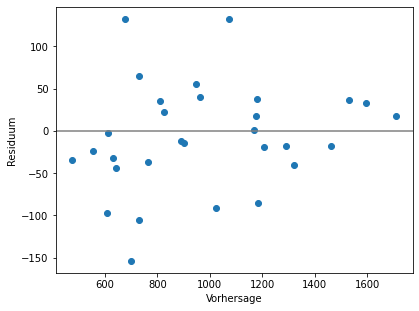

In [ ]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression

wohnungen = pd.read_csv('wohnungen.csv')
X = wohnungen[['flaeche', 'zimmer', 'baujahr', 'entfernung']]
y = wohnungen['miete']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=0)
import matplotlib.pyplot as plt
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression

wohnungen = pd.read_csv('wohnungen.csv')
X = wohnungen[['flaeche', 'zimmer', 'baujahr', 'entfernung']]
y = wohnungen['miete']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=0)
import matplotlib.pyplot as plt
modell = LinearRegression()
modell.fit(X_train, y_train)
vorhersage = modell.predict(X_test)
plt.scatter(vorhersage, y_test - vorhersage)
plt.axhline(0, color='gray')
plt.xlabel('Vorhersage')
plt.ylabel('Residuum')
plt.show()
```

</details>

#### Aufgabe 3.6

Was wird ausgegeben? Überlege zuerst, was ausgegeben wird. Führe dann die Zelle aus und vergleiche.

In [ ]:
from sklearn.metrics import mean_absolute_error, mean_squared_error

echt = [10, 20, 30]
vorhersage = [12, 20, 26]
print(mean_absolute_error(echt, vorhersage))
print(mean_squared_error(echt, vorhersage))

<details>
<summary>Lösung anzeigen (erst selbst überlegen!)</summary>

**Ausgabe:**

```
2.0
6.666666666666667
```

Die Abweichungen sind 2, 0 und 4.
- MAE: `(2 + 0 + 4) / 3 = 2.0`.
- MSE: `(4 + 0 + 16) / 3 = 6.666...`, ausgegeben als `6.666666666666667`. Der große Fehler 4 zählt quadriert viel stärker.

</details>

## 4. Kurven mit Polynomen

#### `PolynomialFeatures`

Eine Gerade kann den Bogen der Fahrrad-Daten nicht beschreiben. Mit einem Trick bleibt die Regression trotzdem linear: `PolynomialFeatures(degree=2)` erzeugt
aus dem Merkmal `x` die Merkmale `x` und `x²` (`include_bias=False` lässt die Spalte mit lauter Einsen weg). Die lineare Regression berechnet dann
`y = m₁·x + m₂·x² + b`, eine **Parabel**. Mit `degree=3` kommt `x³` dazu und so weiter.

In einer Pipeline: `make_pipeline(PolynomialFeatures(degree=2, include_bias=False), LinearRegression())`.

In [ ]:
import pandas as pd
from sklearn.preprocessing import PolynomialFeatures

X = pd.DataFrame({'x': [1, 2, 3]})
print(PolynomialFeatures(degree=2, include_bias=False).fit_transform(X))
print(PolynomialFeatures(degree=3, include_bias=False).fit_transform(X))

#### Grad und Überanpassung

Je höher der Grad, desto kurviger kann die Kurve werden, und desto besser passt sie zu den **Trainingsdaten**. Ab einem gewissen Grad folgt sie aber den
Zufällen der Trainingspunkte und wird auf neuen Daten schlechter: Überanpassung. Bei hohen Graden werden die Zahlen (`x¹⁰` usw.) riesig;
deshalb wird vorher mit `StandardScaler` skaliert. Im Beispiel wird nur mit 15 Tagen trainiert, damit man die Überanpassung gut sieht.

In [ ]:
import pandas as pd

fahrrad = pd.read_csv('fahrrad.csv')
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
import numpy as np
import matplotlib.pyplot as plt

wenig = fahrrad.sample(15, random_state=1)
x = pd.DataFrame({'temperatur': np.linspace(-5, 35, 300)})
plt.scatter(wenig['temperatur'], wenig['ausleihen'], color='black')
for grad in [1, 2, 10]:
    modell = make_pipeline(StandardScaler(), PolynomialFeatures(degree=grad, include_bias=False), LinearRegression())
    modell.fit(wenig[['temperatur']], wenig['ausleihen'])
    plt.plot(x['temperatur'], modell.predict(x), label=f'Grad {grad}')
plt.ylim(-200, 1200)
plt.legend()
plt.show()

#### Aufgabe 4.1

Trainiere eine Parabel (Grad 2) auf den Fahrrad-Trainingsdaten und gib R² auf Trainings- und Testdaten aus, zum Vergleich auch für die Gerade (Grad 1).
3 Nachkommastellen.

**Erwartete Ausgabe:**

```
1 0.735 0.728
2 0.943 0.929
```

In [ ]:
import pandas as pd
from sklearn.model_selection import train_test_split

fahrrad = pd.read_csv('fahrrad.csv')
X = fahrrad[['temperatur']]
y = fahrrad['ausleihen']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=0)
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import pandas as pd
from sklearn.model_selection import train_test_split

fahrrad = pd.read_csv('fahrrad.csv')
X = fahrrad[['temperatur']]
y = fahrrad['ausleihen']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=0)
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
for grad in [1, 2]:
    modell = make_pipeline(PolynomialFeatures(degree=grad, include_bias=False), LinearRegression())
    modell.fit(X_train, y_train)
    print(grad, f'{modell.score(X_train, y_train):.3f} {modell.score(X_test, y_test):.3f}')
```

</details>

#### Aufgabe 4.2

Bei welcher Temperatur sagt die Parabel die meisten Ausleihen voraus? Werte sie an 401 Stellen von -5 bis 35 aus und gib die Temperatur
(eine Nachkommastelle) und die Anzahl (ganze Zahl) aus.

**Erwartete Ausgabe:**

```
24.3 876
```

In [ ]:
import pandas as pd
from sklearn.model_selection import train_test_split

fahrrad = pd.read_csv('fahrrad.csv')
X = fahrrad[['temperatur']]
y = fahrrad['ausleihen']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=0)
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
import numpy as np
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import pandas as pd
from sklearn.model_selection import train_test_split

fahrrad = pd.read_csv('fahrrad.csv')
X = fahrrad[['temperatur']]
y = fahrrad['ausleihen']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=0)
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
import numpy as np
modell = make_pipeline(PolynomialFeatures(degree=2, include_bias=False), LinearRegression())
modell.fit(X_train, y_train)
x = pd.DataFrame({'temperatur': np.linspace(-5, 35, 401)})
werte = modell.predict(x)
i = werte.argmax()
print(f"{x['temperatur'][i]:.1f} {werte[i]:.0f}")
```

</details>

#### Aufgabe 4.3

Gib die Koeffizienten der Parabel (`modell[-1].coef_`, 3 Nachkommastellen) und den Achsenabschnitt (eine Nachkommastelle) aus.
Die Parabel ist `y = m₁·x + m₂·x² + b`.

**Erwartete Ausgabe:**

```
[63.845 -1.312]
99.6
```

In [ ]:
import pandas as pd
from sklearn.model_selection import train_test_split

fahrrad = pd.read_csv('fahrrad.csv')
X = fahrrad[['temperatur']]
y = fahrrad['ausleihen']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=0)
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import pandas as pd
from sklearn.model_selection import train_test_split

fahrrad = pd.read_csv('fahrrad.csv')
X = fahrrad[['temperatur']]
y = fahrrad['ausleihen']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=0)
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
modell = make_pipeline(PolynomialFeatures(degree=2, include_bias=False), LinearRegression())
modell.fit(X_train, y_train)
print(modell[-1].coef_.round(3))
print(f'{modell[-1].intercept_:.1f}')
```

</details>

#### Aufgabe 4.4

Gib für die Grade 1 bis 8 R² auf Trainings- und Testdaten der Fahrrad-Daten aus (mit `StandardScaler` vor `PolynomialFeatures`, 3 Nachkommastellen).

**Erwartete Ausgabe:**

```
1 0.735 0.728
2 0.943 0.929
3 0.959 0.954
4 0.968 0.957
5 0.968 0.957
6 0.968 0.959
7 0.968 0.959
8 0.969 0.960
```

In [ ]:
import pandas as pd
from sklearn.model_selection import train_test_split

fahrrad = pd.read_csv('fahrrad.csv')
X = fahrrad[['temperatur']]
y = fahrrad['ausleihen']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=0)
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import pandas as pd
from sklearn.model_selection import train_test_split

fahrrad = pd.read_csv('fahrrad.csv')
X = fahrrad[['temperatur']]
y = fahrrad['ausleihen']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=0)
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
for grad in range(1, 9):
    modell = make_pipeline(StandardScaler(), PolynomialFeatures(degree=grad, include_bias=False), LinearRegression())
    modell.fit(X_train, y_train)
    print(grad, f'{modell.score(X_train, y_train):.3f} {modell.score(X_test, y_test):.3f}')
```

</details>

#### Aufgabe 4.5

Wiederhole die vorige Aufgabe mit nur 15 Trainingstagen (`fahrrad.sample(15, random_state=1)`, getestet mit **allen** übrigen Tagen,
`fahrrad.drop(wenig.index)`) für die Grade 1, 2, 4, 6, 8 und 10. Jetzt sieht man die Überanpassung deutlich. Ein negatives R² bedeutet: schlechter,
als immer den Mittelwert vorherzusagen. Bei den hohen Graden schießt die Kurve zwischen und neben den 15 Trainingspunkten weit nach oben oder unten.

**Erwartete Ausgabe:**

```
1 0.862 0.695
2 0.975 0.903
4 0.984 0.512
6 0.985 0.907
8 0.991 -66.425
10 0.993 -5202.557
```

In [ ]:
import pandas as pd

fahrrad = pd.read_csv('fahrrad.csv')
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import pandas as pd

fahrrad = pd.read_csv('fahrrad.csv')
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
wenig = fahrrad.sample(15, random_state=1)
rest = fahrrad.drop(wenig.index)
for grad in [1, 2, 4, 6, 8, 10]:
    modell = make_pipeline(StandardScaler(), PolynomialFeatures(degree=grad, include_bias=False), LinearRegression())
    modell.fit(wenig[['temperatur']], wenig['ausleihen'])
    print(grad, f"{modell.score(wenig[['temperatur']], wenig['ausleihen']):.3f} {modell.score(rest[['temperatur']], rest['ausleihen']):.3f}")
```

</details>

#### Aufgabe 4.6

Zeichne die Fahrrad-Daten als Punkte und die Parabel (trainiert mit allen Daten) als rote Linie von -5 bis 35 °C (200 Punkte).

**Erwartete Ausgabe:**



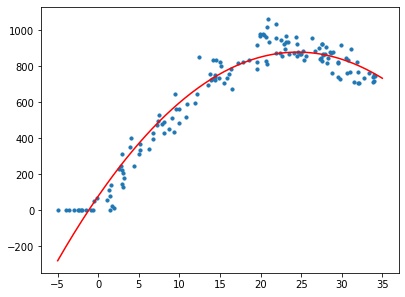

In [ ]:
import pandas as pd

fahrrad = pd.read_csv('fahrrad.csv')
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
import numpy as np
import matplotlib.pyplot as plt
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import pandas as pd

fahrrad = pd.read_csv('fahrrad.csv')
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
import numpy as np
import matplotlib.pyplot as plt
modell = make_pipeline(PolynomialFeatures(degree=2, include_bias=False), LinearRegression())
modell.fit(fahrrad[['temperatur']], fahrrad['ausleihen'])
x = pd.DataFrame({'temperatur': np.linspace(-5, 35, 200)})
plt.scatter(fahrrad['temperatur'], fahrrad['ausleihen'], s=10)
plt.plot(x['temperatur'], modell.predict(x), color='red')
plt.show()
```

</details>

#### Aufgabe 4.7

Finde den besten Grad (1 bis 8) für die Fahrrad-Daten mit 5-facher Kreuzvalidierung (`cross_val_score`, bewertet mit R², alle Daten).
Gib für jeden Grad den Mittelwert aus (3 Nachkommastellen).

**Erwartete Ausgabe:**

```
1 0.689
2 0.931
3 0.951
4 0.959
5 0.957
6 0.958
7 0.957
8 0.958
```

In [ ]:
import pandas as pd

fahrrad = pd.read_csv('fahrrad.csv')
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.model_selection import cross_val_score
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import pandas as pd

fahrrad = pd.read_csv('fahrrad.csv')
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.model_selection import cross_val_score
X = fahrrad[['temperatur']]
y = fahrrad['ausleihen']
for grad in range(1, 9):
    modell = make_pipeline(StandardScaler(), PolynomialFeatures(degree=grad, include_bias=False), LinearRegression())
    print(grad, f'{cross_val_score(modell, X, y, cv=5).mean():.3f}')
```

</details>

#### Aufgabe 4.8

Was wird ausgegeben? Überlege zuerst, was ausgegeben wird. Führe dann die Zelle aus und vergleiche.

In [ ]:
import pandas as pd
from sklearn.preprocessing import PolynomialFeatures

X = pd.DataFrame({'x': [2, 3]})
print(PolynomialFeatures(degree=3, include_bias=False).fit_transform(X))

<details>
<summary>Lösung anzeigen (erst selbst überlegen!)</summary>

**Ausgabe:**

```
[[ 2.  4.  8.]
 [ 3.  9. 27.]]
```

Für jedes `x` entstehen die Spalten `x`, `x²` und `x³`: für 2 die Werte 2, 4, 8 und für 3 die Werte 3, 9, 27.
Ausgabe: `[[ 2.  4.  8.]` und `[ 3.  9. 27.]]`.

</details>

## 5. Bäume und Nachbarn für Zahlen

#### `DecisionTreeRegressor` und `KNeighborsRegressor`

Bäume und k-nächste Nachbarn gibt es auch für die Regression:

- `DecisionTreeRegressor(max_depth=3)`: Jedes Blatt sagt den **Mittelwert** der Trainingsbeispiele vorher, die dort ankommen. Die Vorhersage ist eine Treppe.
- `KNeighborsRegressor(n_neighbors=10)`: Die Vorhersage ist der **Mittelwert** der Zielwerte der `k` nächsten Nachbarn.

Beide können krumme Zusammenhänge lernen, ohne dass man vorher den Grad eines Polynoms wählen muss, sagen aber außerhalb der Trainingsdaten nur konstante Werte voraus.

In [ ]:
import pandas as pd
from sklearn.model_selection import train_test_split

fahrrad = pd.read_csv('fahrrad.csv')
X = fahrrad[['temperatur']]
y = fahrrad['ausleihen']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=0)
import numpy as np
from sklearn.tree import DecisionTreeRegressor
from sklearn.neighbors import KNeighborsRegressor
import matplotlib.pyplot as plt

baum = DecisionTreeRegressor(max_depth=3, random_state=0)
baum.fit(X_train, y_train)
nachbarn = KNeighborsRegressor(n_neighbors=10)
nachbarn.fit(X_train, y_train)
print(f'Baum {baum.score(X_test, y_test):.3f}, Nachbarn {nachbarn.score(X_test, y_test):.3f}')
x = pd.DataFrame({'temperatur': np.linspace(-10, 40, 500)})
plt.scatter(X_train['temperatur'], y_train, s=10, color='gray')
plt.plot(x['temperatur'], baum.predict(x), label='Baum')
plt.plot(x['temperatur'], nachbarn.predict(x), label='k-NN')
plt.legend()
plt.show()

#### Aufgabe 5.1

Gib für Regressionsbäume mit `max_depth` von 1 bis 8 auf den Fahrrad-Daten R² auf Trainings- und Testdaten aus (3 Nachkommastellen).

**Erwartete Ausgabe:**

```
1 0.838 0.715
2 0.935 0.894
3 0.959 0.924
4 0.978 0.953
5 0.986 0.951
6 0.989 0.940
7 0.992 0.927
8 0.996 0.913
```

In [ ]:
import pandas as pd
from sklearn.model_selection import train_test_split

fahrrad = pd.read_csv('fahrrad.csv')
X = fahrrad[['temperatur']]
y = fahrrad['ausleihen']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=0)
from sklearn.tree import DecisionTreeRegressor
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import pandas as pd
from sklearn.model_selection import train_test_split

fahrrad = pd.read_csv('fahrrad.csv')
X = fahrrad[['temperatur']]
y = fahrrad['ausleihen']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=0)
from sklearn.tree import DecisionTreeRegressor
for tiefe in range(1, 9):
    modell = DecisionTreeRegressor(max_depth=tiefe, random_state=0)
    modell.fit(X_train, y_train)
    print(tiefe, f'{modell.score(X_train, y_train):.3f} {modell.score(X_test, y_test):.3f}')
```

</details>

#### Aufgabe 5.2

Gib den Regressionsbaum der Tiefe 2 für die Fahrrad-Trainingsdaten mit `export_text()` aus. In den Blättern steht `value`, der vorhergesagte Mittelwert.

**Erwartete Ausgabe:**

```
|--- temperatur <= 9.4
|   |--- temperatur <= 3.6
|   |   |--- value: [69.0]
|   |--- temperatur >  3.6
|   |   |--- value: [412.0]
|--- temperatur >  9.4
|   |--- temperatur <= 12.1
|   |   |--- value: [548.3]
|   |--- temperatur >  12.1
|   |   |--- value: [838.6]
```

In [ ]:
import pandas as pd
from sklearn.model_selection import train_test_split

fahrrad = pd.read_csv('fahrrad.csv')
X = fahrrad[['temperatur']]
y = fahrrad['ausleihen']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=0)
from sklearn.tree import DecisionTreeRegressor, export_text
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import pandas as pd
from sklearn.model_selection import train_test_split

fahrrad = pd.read_csv('fahrrad.csv')
X = fahrrad[['temperatur']]
y = fahrrad['ausleihen']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=0)
from sklearn.tree import DecisionTreeRegressor, export_text
modell = DecisionTreeRegressor(max_depth=2, random_state=0)
modell.fit(X_train, y_train)
print(export_text(modell, feature_names=['temperatur'], decimals=1))
```

</details>

#### Aufgabe 5.3

Gib für `KNeighborsRegressor` mit `k` = 1, 3, 5, 10, 20, 50 und 100 R² auf Trainings- und Testdaten der Fahrrad-Daten aus (3 Nachkommastellen).

**Erwartete Ausgabe:**

```
1 1.000 0.915
3 0.980 0.950
5 0.977 0.952
10 0.972 0.955
20 0.958 0.954
50 0.726 0.750
100 0.083 0.070
```

In [ ]:
import pandas as pd
from sklearn.model_selection import train_test_split

fahrrad = pd.read_csv('fahrrad.csv')
X = fahrrad[['temperatur']]
y = fahrrad['ausleihen']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=0)
from sklearn.neighbors import KNeighborsRegressor
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import pandas as pd
from sklearn.model_selection import train_test_split

fahrrad = pd.read_csv('fahrrad.csv')
X = fahrrad[['temperatur']]
y = fahrrad['ausleihen']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=0)
from sklearn.neighbors import KNeighborsRegressor
for k in [1, 3, 5, 10, 20, 50, 100]:
    modell = KNeighborsRegressor(n_neighbors=k)
    modell.fit(X_train, y_train)
    print(k, f'{modell.score(X_train, y_train):.3f} {modell.score(X_test, y_test):.3f}')
```

</details>

#### Aufgabe 5.4

Was sagen die drei Modelle (Parabel, Baum mit Tiefe 3, k-NN mit `k = 10`, alle mit den Trainingsdaten trainiert) für -15 °C und 45 °C voraus?
Diese Temperaturen liegen außerhalb der Daten. Gib für jedes Modell den Namen und die beiden Vorhersagen aus (ganze Zahlen).

**Erwartete Ausgabe:**

```
Parabel [-1153.   316.]
Baum [ 33. 766.]
k-NN [  5. 758.]
```

In [ ]:
import pandas as pd
from sklearn.model_selection import train_test_split

fahrrad = pd.read_csv('fahrrad.csv')
X = fahrrad[['temperatur']]
y = fahrrad['ausleihen']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=0)
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.tree import DecisionTreeRegressor
from sklearn.neighbors import KNeighborsRegressor
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import pandas as pd
from sklearn.model_selection import train_test_split

fahrrad = pd.read_csv('fahrrad.csv')
X = fahrrad[['temperatur']]
y = fahrrad['ausleihen']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=0)
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.tree import DecisionTreeRegressor
from sklearn.neighbors import KNeighborsRegressor
modelle = {'Parabel': make_pipeline(PolynomialFeatures(degree=2, include_bias=False), LinearRegression()),
           'Baum': DecisionTreeRegressor(max_depth=3, random_state=0),
           'k-NN': KNeighborsRegressor(n_neighbors=10)}
neu = pd.DataFrame({'temperatur': [-15, 45]})
for name, modell in modelle.items():
    modell.fit(X_train, y_train)
    print(name, modell.predict(neu).round())
```

</details>

#### Aufgabe 5.5

Vergleiche auf den Mietdaten (alle vier Merkmale, Aufteilung in der Zelle): lineare Regression, Regressionsbaum (`max_depth=5`) und skaliertes k-NN (`k = 5`).
Gib Namen, R² und MAE auf den Testdaten aus (3 bzw. 2 Nachkommastellen).

**Erwartete Ausgabe:**

```
linear 0.967 48.39
Baum 0.905 81.65
k-NN 0.884 97.17
```

In [ ]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression

wohnungen = pd.read_csv('wohnungen.csv')
X = wohnungen[['flaeche', 'zimmer', 'baujahr', 'entfernung']]
y = wohnungen['miete']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=0)
from sklearn.tree import DecisionTreeRegressor
from sklearn.neighbors import KNeighborsRegressor
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression

wohnungen = pd.read_csv('wohnungen.csv')
X = wohnungen[['flaeche', 'zimmer', 'baujahr', 'entfernung']]
y = wohnungen['miete']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=0)
from sklearn.tree import DecisionTreeRegressor
from sklearn.neighbors import KNeighborsRegressor
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error
modelle = {'linear': LinearRegression(),
           'Baum': DecisionTreeRegressor(max_depth=5, random_state=0),
           'k-NN': make_pipeline(StandardScaler(), KNeighborsRegressor(n_neighbors=5))}
for name, modell in modelle.items():
    modell.fit(X_train, y_train)
    print(name, f'{modell.score(X_test, y_test):.3f} {mean_absolute_error(y_test, modell.predict(X_test)):.2f}')
```

</details>

#### Aufgabe 5.6

Was wird ausgegeben? Überlege zuerst, was ausgegeben wird. Führe dann die Zelle aus und vergleiche.

In [ ]:
import pandas as pd
from sklearn.neighbors import KNeighborsRegressor

X = pd.DataFrame({'x': [1, 2, 3, 10]})
y = [10, 20, 30, 100]
modell = KNeighborsRegressor(n_neighbors=2)
modell.fit(X, y)
print(modell.predict(pd.DataFrame({'x': [1.4, 9, 50]})))

<details>
<summary>Lösung anzeigen (erst selbst überlegen!)</summary>

**Ausgabe:**

```
[15. 65. 65.]
```

Die Vorhersage ist der Mittelwert der Zielwerte der 2 nächsten Nachbarn:
- für 1.4: Nachbarn 1 und 2, also `(10 + 20) / 2 = 15`,
- für 9: Nachbarn 10 und 3, also `(100 + 30) / 2 = 65`,
- für 50: ebenfalls 10 und 3, also `65`. Weiter weg ändert sich nichts mehr.

Ausgabe: `[15. 65. 65.]`.

</details>

## 6. Gemischte Übungen

#### Aufgabe 6.1

`load_diabetes` enthält Daten von 442 Patienten: 10 (bereits skalierte) Messwerte wie Alter, BMI und Blutdruck und als Zielwert ein Maß für das Fortschreiten
der Krankheit nach einem Jahr. Gib die Form der Tabelle aus und zeige die Korrelationen der Merkmale mit dem Zielwert an
(`daten.corr()['target']`, absteigend sortiert, 3 Nachkommastellen).

**Erwartete Ausgabe:**

```
(442, 11)
target    1.000
bmi       0.586
s5        0.566
bp        0.441
s4        0.430
s6        0.382
s1        0.212
age       0.188
s2        0.174
sex       0.043
s3       -0.395
Name: target, dtype: float64
```

In [ ]:
import pandas as pd
from sklearn.datasets import load_diabetes

daten = load_diabetes(as_frame=True).frame
X = daten.drop(columns='target')
y = daten['target']
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import pandas as pd
from sklearn.datasets import load_diabetes

daten = load_diabetes(as_frame=True).frame
X = daten.drop(columns='target')
y = daten['target']
print(daten.shape)
print(daten.corr()['target'].sort_values(ascending=False).round(3))
```

</details>

#### Aufgabe 6.2

Vergleiche mit 5-facher Kreuzvalidierung (R²) auf den Diabetes-Daten: lineare Regression, Regressionsbaum (`max_depth=3`) und k-NN (`k = 20`).
Gib Namen und mittleres R² aus (3 Nachkommastellen).

**Erwartete Ausgabe:**

```
linear 0.482
Baum 0.309
k-NN 0.449
```

In [ ]:
import pandas as pd
from sklearn.datasets import load_diabetes

daten = load_diabetes(as_frame=True).frame
X = daten.drop(columns='target')
y = daten['target']
from sklearn.model_selection import cross_val_score
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.neighbors import KNeighborsRegressor
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import pandas as pd
from sklearn.datasets import load_diabetes

daten = load_diabetes(as_frame=True).frame
X = daten.drop(columns='target')
y = daten['target']
from sklearn.model_selection import cross_val_score
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.neighbors import KNeighborsRegressor
modelle = {'linear': LinearRegression(),
           'Baum': DecisionTreeRegressor(max_depth=3, random_state=0),
           'k-NN': KNeighborsRegressor(n_neighbors=20)}
for name, modell in modelle.items():
    print(name, f'{cross_val_score(modell, X, y, cv=5).mean():.3f}')
```

</details>

#### Aufgabe 6.3

Finde mit `GridSearchCV` (5-fach) für die Mietdaten (alle Daten) den besten Grad (1, 2, 3) einer Pipeline aus `StandardScaler`, `PolynomialFeatures`
(`include_bias=False`) und `LinearRegression`. Gib die besten Einstellungen und das mittlere R² aus (3 Nachkommastellen). Der Name der Einstellung ist
`'polynomialfeatures__degree'`.

**Erwartete Ausgabe:**

```
{'polynomialfeatures__degree': 1}
0.964
```

In [ ]:
import pandas as pd

wohnungen = pd.read_csv('wohnungen.csv')
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.model_selection import GridSearchCV
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import pandas as pd

wohnungen = pd.read_csv('wohnungen.csv')
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.model_selection import GridSearchCV
X = wohnungen[['flaeche', 'zimmer', 'baujahr', 'entfernung']]
y = wohnungen['miete']
modell = make_pipeline(StandardScaler(), PolynomialFeatures(include_bias=False), LinearRegression())
suche = GridSearchCV(modell, {'polynomialfeatures__degree': [1, 2, 3]}, cv=5)
suche.fit(X, y)
print(suche.best_params_)
print(f'{suche.best_score_:.3f}')
```

</details>

#### Aufgabe 6.4

Ein neuronales Netz kann auch Zahlen vorhersagen: `MLPRegressor` aus `sklearn.neural_network`. Trainiere eine Pipeline aus `StandardScaler` und
`MLPRegressor(hidden_layer_sizes=(50,), max_iter=5000, learning_rate_init=0.01, random_state=0)` auf den Fahrrad-Trainingsdaten. Die Zielwerte müssen dabei
ebenfalls klein sein: Teile sie beim Training durch 1000 und multipliziere die Vorhersagen wieder mit 1000. Gib R² auf den Testdaten aus
(`r2_score`, 3 Nachkommastellen).

**Erwartete Ausgabe:**

```
0.940
```

In [ ]:
import pandas as pd
from sklearn.model_selection import train_test_split

fahrrad = pd.read_csv('fahrrad.csv')
X = fahrrad[['temperatur']]
y = fahrrad['ausleihen']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=0)
from sklearn.neural_network import MLPRegressor
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import r2_score
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import pandas as pd
from sklearn.model_selection import train_test_split

fahrrad = pd.read_csv('fahrrad.csv')
X = fahrrad[['temperatur']]
y = fahrrad['ausleihen']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=0)
from sklearn.neural_network import MLPRegressor
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import r2_score
modell = make_pipeline(StandardScaler(), MLPRegressor(hidden_layer_sizes=(50,), max_iter=5000, learning_rate_init=0.01, random_state=0))
modell.fit(X_train, y_train / 1000)
vorhersage = modell.predict(X_test) * 1000
print(f'{r2_score(y_test, vorhersage):.3f}')
```

</details>

#### Aufgabe 6.5

Zeichne die Fahrrad-Daten mit den Vorhersagen von vier Modellen (Gerade, Parabel, Baum mit Tiefe 4, k-NN mit `k = 10`, alle mit allen Daten trainiert)
für -5 bis 35 °C (300 Punkte) in einem Diagramm mit Legende.

**Erwartete Ausgabe:**



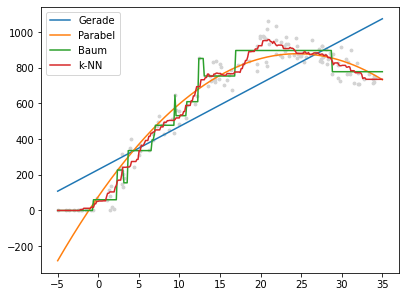

In [ ]:
import pandas as pd

fahrrad = pd.read_csv('fahrrad.csv')
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
import numpy as np
from sklearn.tree import DecisionTreeRegressor
from sklearn.neighbors import KNeighborsRegressor
import matplotlib.pyplot as plt
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import pandas as pd

fahrrad = pd.read_csv('fahrrad.csv')
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
import numpy as np
from sklearn.tree import DecisionTreeRegressor
from sklearn.neighbors import KNeighborsRegressor
import matplotlib.pyplot as plt
X = fahrrad[['temperatur']]
y = fahrrad['ausleihen']
modelle = {'Gerade': LinearRegression(),
           'Parabel': make_pipeline(PolynomialFeatures(degree=2, include_bias=False), LinearRegression()),
           'Baum': DecisionTreeRegressor(max_depth=4, random_state=0),
           'k-NN': KNeighborsRegressor(n_neighbors=10)}
x = pd.DataFrame({'temperatur': np.linspace(-5, 35, 300)})
plt.scatter(X['temperatur'], y, s=8, color='lightgray')
for name, modell in modelle.items():
    modell.fit(X, y)
    plt.plot(x['temperatur'], modell.predict(x), label=name)
plt.legend()
plt.show()
```

</details>

#### Aufgabe 6.6

Erfinde eine eigene Regressionsaufgabe (z. B. Bremsweg in Abhängigkeit von der Geschwindigkeit, Preis eines Gebrauchtwagens nach Alter und Kilometerstand)
mit selbst erzeugten Daten und vergleiche mindestens zwei Modelle mit Kreuzvalidierung.

In [ ]:
# your code

<details>
<summary>Beispiellösung anzeigen (erst selbst probieren!)</summary>

```python
import numpy as np
import pandas as pd
from sklearn.model_selection import cross_val_score
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import PolynomialFeatures

rng = np.random.default_rng(1)
tempo = rng.uniform(20, 130, 80)
bremsweg = (tempo / 10) ** 2 / 2 + 3 * tempo / 10 + rng.normal(0, 5, 80)
X = pd.DataFrame({'tempo': tempo})
for name, modell in {'Gerade': LinearRegression(),
                     'Parabel': make_pipeline(PolynomialFeatures(degree=2, include_bias=False), LinearRegression())}.items():
    print(name, f'{cross_val_score(modell, X, bremsweg, cv=5).mean():.3f}')
```

</details>